In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Financial Fraud Detection Project")
print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Matplotlib is building the font cache; this may take a moment.


Financial Fraud Detection Project
All libraries imported successfully!
Pandas: 3.1.1
NumPy: 2.4.6


In [2]:
import pandas as pd
from pathlib import Path

# Find the CSV file in our project folder
csv_files = list(Path.cwd().glob("*.csv"))

print("CSV files found:", csv_files)

# Load the first 100,000 transactions for initial exploration
df = pd.read_csv(csv_files[0], nrows=100000)

# Display the first five rows
df.head()

CSV files found: [WindowsPath('c:/Users/meenutty/OneDrive/Desktop/Financial_Fraud_Detection/PS_20174392719_1491204439457_log.csv')]


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (100000, 11)

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            100000 non-null  int64  
 1   type            100000 non-null  str    
 2   amount          100000 non-null  float64
 3   nameOrig        100000 non-null  str    
 4   oldbalanceOrg   100000 non-null  float64
 5   newbalanceOrig  100000 non-null  float64
 6   nameDest        100000 non-null  str    
 7   oldbalanceDest  100000 non-null  float64
 8   newbalanceDest  100000 non-null  float64
 9   isFraud         100000 non-null  int64  
 10  isFlaggedFraud  100000 non-null  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 8.4 MB


In [4]:
fraud_counts = df['isFraud'].value_counts()

print("Fraud Distribution:")
print(fraud_counts)

Fraud Distribution:
isFraud
0    99884
1      116
Name: count, dtype: int64


In [5]:
fraud_percentage = df['isFraud'].value_counts(normalize=True) * 100

print("Fraud Percentage:")
print(fraud_percentage)

Fraud Percentage:
isFraud
0    99.884
1     0.116
Name: proportion, dtype: float64


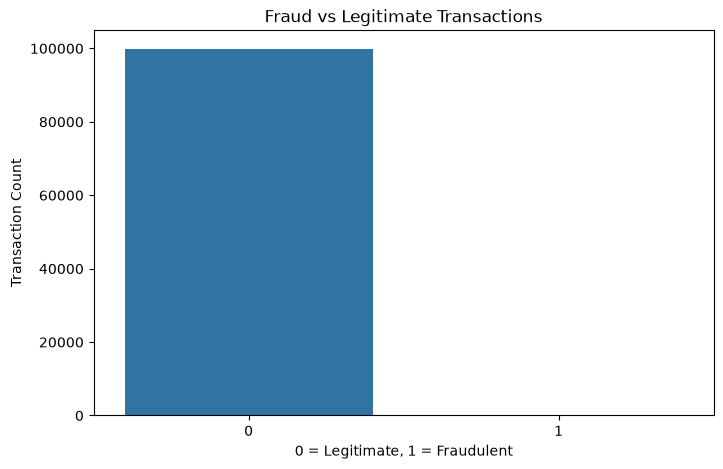

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='isFraud')

plt.title('Fraud vs Legitimate Transactions')
plt.xlabel('0 = Legitimate, 1 = Fraudulent')
plt.ylabel('Transaction Count')

plt.show()

In [7]:
print("Transaction Type Distribution:")
print(df['type'].value_counts())


Transaction Type Distribution:
type
PAYMENT     39512
CASH_OUT    30718
CASH_IN     20185
TRANSFER     8597
DEBIT         988
Name: count, dtype: int64


In [8]:
fraud_by_type = df.groupby('type')['isFraud'].sum()

print("Fraud Cases by Transaction Type:")
print(fraud_by_type)

Fraud Cases by Transaction Type:
type
CASH_IN      0
CASH_OUT    59
DEBIT        0
PAYMENT      0
TRANSFER    57
Name: isFraud, dtype: int64


In [9]:
fraud_rate = df.groupby('type')['isFraud'].mean() * 100

print("Fraud Rate by Transaction Type:")
print(fraud_rate.sort_values(ascending=False))

Fraud Rate by Transaction Type:
type
TRANSFER    0.663022
CASH_OUT    0.192070
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64


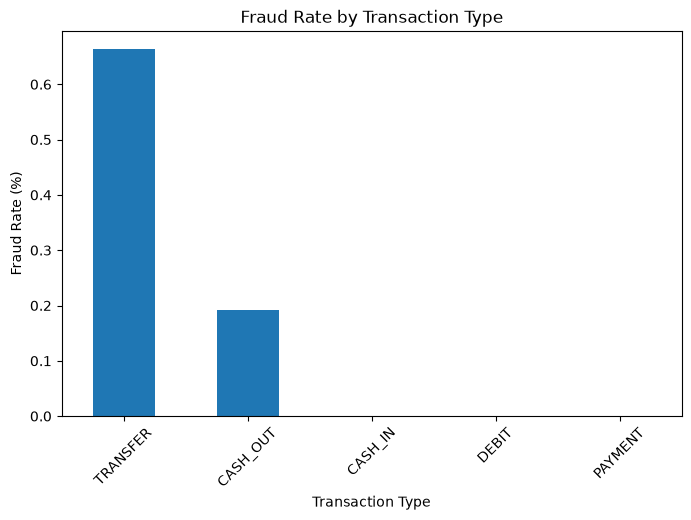

In [10]:
plt.figure(figsize=(8, 5))

fraud_rate.sort_values(ascending=False).plot(kind='bar')

plt.title('Fraud Rate by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)

plt.show()

In [11]:
print("Transaction Amount Statistics:")
print(df['amount'].describe())

Transaction Amount Statistics:
count    1.000000e+05
mean     1.736022e+05
std      3.443003e+05
min      3.200000e-01
25%      9.963562e+03
50%      5.274552e+04
75%      2.117631e+05
max      1.000000e+07
Name: amount, dtype: float64


In [12]:
print("Average Amount by Transaction Class:")

print(df.groupby('isFraud')['amount'].mean())

Average Amount by Transaction Class:
isFraud
0    173174.873646
1    541578.424138
Name: amount, dtype: float64


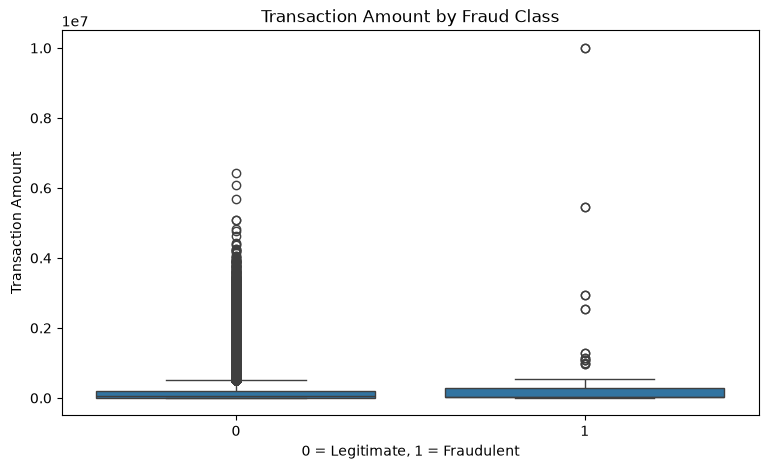

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='isFraud', y='amount')

plt.title('Transaction Amount by Fraud Class')
plt.xlabel('0 = Legitimate, 1 = Fraudulent')
plt.ylabel('Transaction Amount')

plt.show()

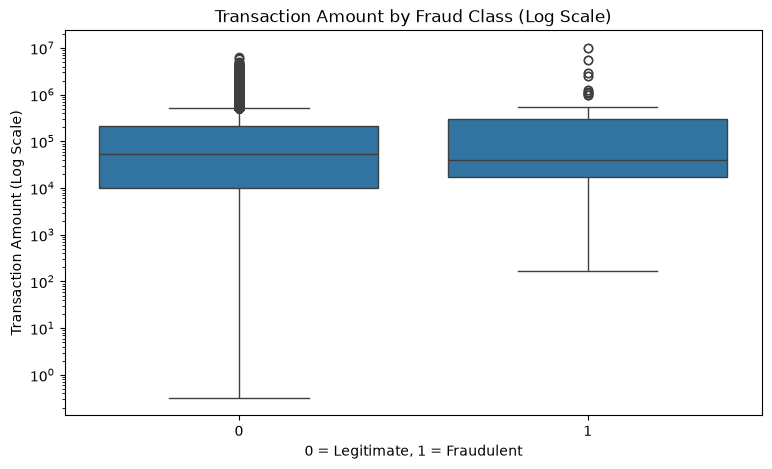

In [14]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='isFraud', y='amount')

plt.yscale('log')

plt.title('Transaction Amount by Fraud Class (Log Scale)')
plt.xlabel('0 = Legitimate, 1 = Fraudulent')
plt.ylabel('Transaction Amount (Log Scale)')

plt.show()

In [15]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [16]:
print("Number of Duplicate Rows:")
print(df.duplicated().sum())

Number of Duplicate Rows:
0


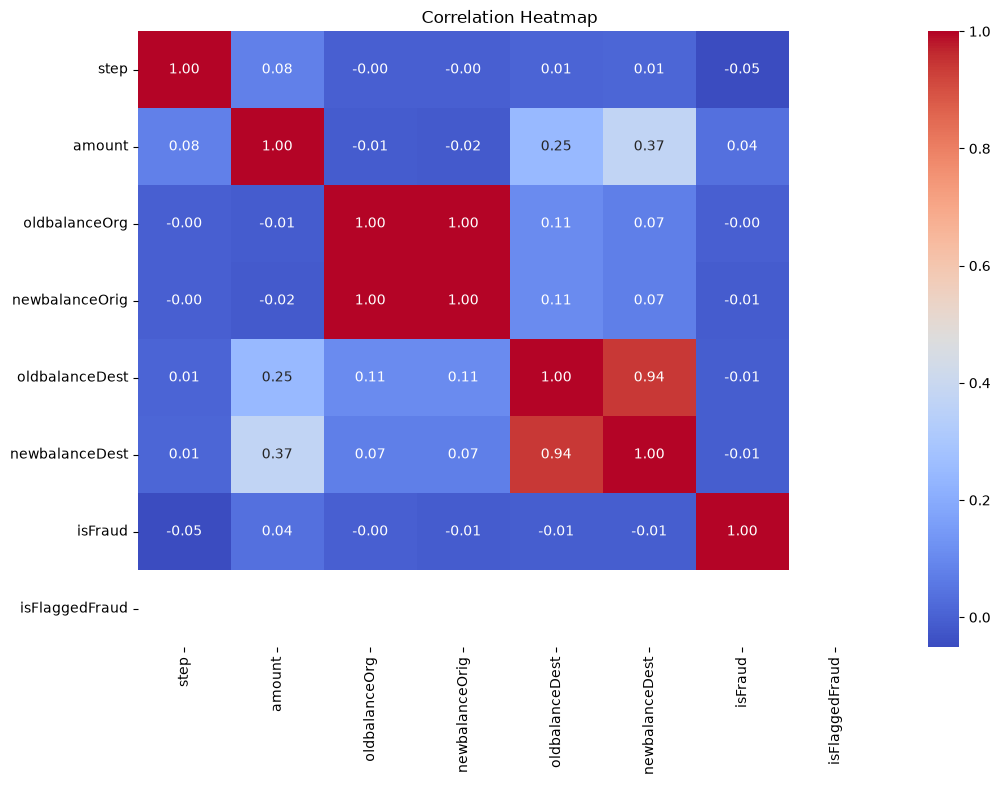

In [17]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=['number'])

correlation = numeric_df.corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

In [18]:
print(correlation['isFraud'].sort_values(ascending=False))

isFraud           1.000000
amount            0.036422
oldbalanceOrg    -0.004144
newbalanceDest   -0.006394
oldbalanceDest   -0.009266
newbalanceOrig   -0.010872
step             -0.051329
isFlaggedFraud         NaN
Name: isFraud, dtype: float64


In [19]:
print("Categorical Columns:")
print(df.select_dtypes(include=['object', 'str']).columns.tolist())

print("\nNumerical Columns:")
print(df.select_dtypes(include=['number']).columns.tolist())

Categorical Columns:
['type', 'nameOrig', 'nameDest']

Numerical Columns:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [20]:
# Separate input features and target
X = df.drop(columns=[
    'isFraud',
    'nameOrig',
    'nameDest',
    'isFlaggedFraud'
])

y = df['isFraud']

# Convert transaction type into numerical columns
X = pd.get_dummies(X, columns=['type'], dtype=int)

print("Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Feature Dataset Shape: (100000, 11)
Target Dataset Shape: (100000,)

Feature Columns:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Fraud Distribution:")
print(y_train.value_counts())

print("\nTesting Fraud Distribution:")
print(y_test.value_counts())

Training Features: (80000, 11)
Testing Features: (20000, 11)

Training Fraud Distribution:
isFraud
0    79907
1       93
Name: count, dtype: int64

Testing Fraud Distribution:
isFraud
0    19977
1       23
Name: count, dtype: int64


In [22]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [23]:
# Predict fraud on testing data
y_pred = model.predict(X_test)

print("First 20 Actual Values:")
print(y_test.head(20).values)

print("\nFirst 20 Predicted Values:")
print(y_pred[:20])

First 20 Actual Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 Predicted Values:
[0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0]


In [24]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.96     19977
           1       0.02      0.96      0.03        23

    accuracy                           0.93     20000
   macro avg       0.51      0.94      0.50     20000
weighted avg       1.00      0.93      0.96     20000



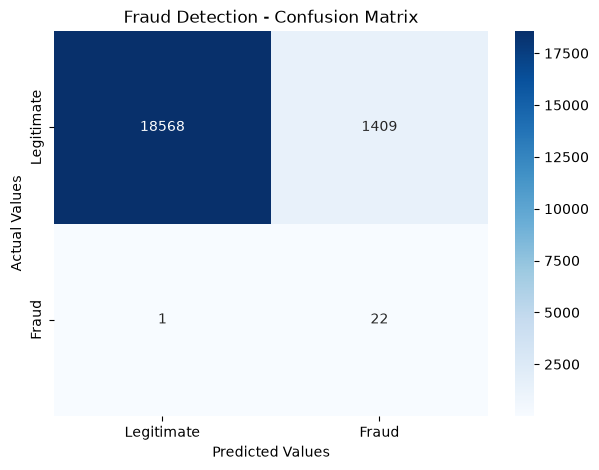

Confusion Matrix:
[[18568  1409]
 [    1    22]]


In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Fraud Detection - Confusion Matrix')

plt.show()

print("Confusion Matrix:")
print(cm)

In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
rf_pred = rf_model.predict(X_test)

print("First 20 Random Forest Predictions:")
print(rf_pred[:20])

First 20 Random Forest Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [28]:
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19977
           1       0.92      0.48      0.63        23

    accuracy                           1.00     20000
   macro avg       0.96      0.74      0.81     20000
weighted avg       1.00      1.00      1.00     20000



In [29]:
rf_cm = confusion_matrix(y_test, rf_pred)

print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[19976     1]
 [   12    11]]


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Create training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Train a temporary Random Forest model
rf_tuning_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_tuning_model.fit(X_subtrain, y_subtrain)

print("Validation model trained successfully!")
print("Validation dataset:", X_val.shape)

Validation model trained successfully!
Validation dataset: (16000, 11)


In [31]:
# Get fraud probabilities for validation data
y_val_proba = rf_tuning_model.predict_proba(X_val)[:, 1]

print("First 10 Fraud Probabilities:")
print(y_val_proba[:10])


First 10 Fraud Probabilities:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:
    val_pred = (y_val_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_val, val_pred, zero_division=0))
    print("Recall:", recall_score(y_val, val_pred, zero_division=0))
    print("F1 Score:", f1_score(y_val, val_pred, zero_division=0))


Threshold: 0.1
Precision: 0.2545454545454545
Recall: 0.7368421052631579
F1 Score: 0.3783783783783784

Threshold: 0.2
Precision: 0.43333333333333335
Recall: 0.6842105263157895
F1 Score: 0.5306122448979592

Threshold: 0.3
Precision: 0.5714285714285714
Recall: 0.631578947368421
F1 Score: 0.6

Threshold: 0.4
Precision: 0.6875
Recall: 0.5789473684210527
F1 Score: 0.6285714285714286

Threshold: 0.5
Precision: 0.6875
Recall: 0.5789473684210527
F1 Score: 0.6285714285714286


In [33]:
from sklearn.metrics import confusion_matrix, classification_report

val_pred_04 = (y_val_proba >= 0.4).astype(int)

print("Validation Confusion Matrix:")
print(confusion_matrix(y_val, val_pred_04))

print("\nValidation Classification Report:")
print(classification_report(y_val, val_pred_04))

Validation Confusion Matrix:
[[15976     5]
 [    8    11]]

Validation Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     15981
           1       0.69      0.58      0.63        19

    accuracy                           1.00     16000
   macro avg       0.84      0.79      0.81     16000
weighted avg       1.00      1.00      1.00     16000



In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

final_rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(X_train, y_train)

# Predict fraud probabilities on test data
y_test_proba = final_rf_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
final_threshold = 0.4
y_test_pred = (y_test_proba >= final_threshold).astype(int)

print("Final Test Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nFinal Test Classification Report:")
print(classification_report(y_test, y_test_pred))

Final Test Confusion Matrix:
[[19976     1]
 [    8    15]]

Final Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19977
           1       0.94      0.65      0.77        23

    accuracy                           1.00     20000
   macro avg       0.97      0.83      0.88     20000
weighted avg       1.00      1.00      1.00     20000



In [35]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': final_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)


           Feature  Importance
3   newbalanceOrig    0.181750
2    oldbalanceOrg    0.176399
0             step    0.128248
9     type_PAYMENT    0.117838
4   oldbalanceDest    0.112438
5   newbalanceDest    0.083235
1           amount    0.082644
10   type_TRANSFER    0.060774
7    type_CASH_OUT    0.034890
6     type_CASH_IN    0.021053
8       type_DEBIT    0.000732


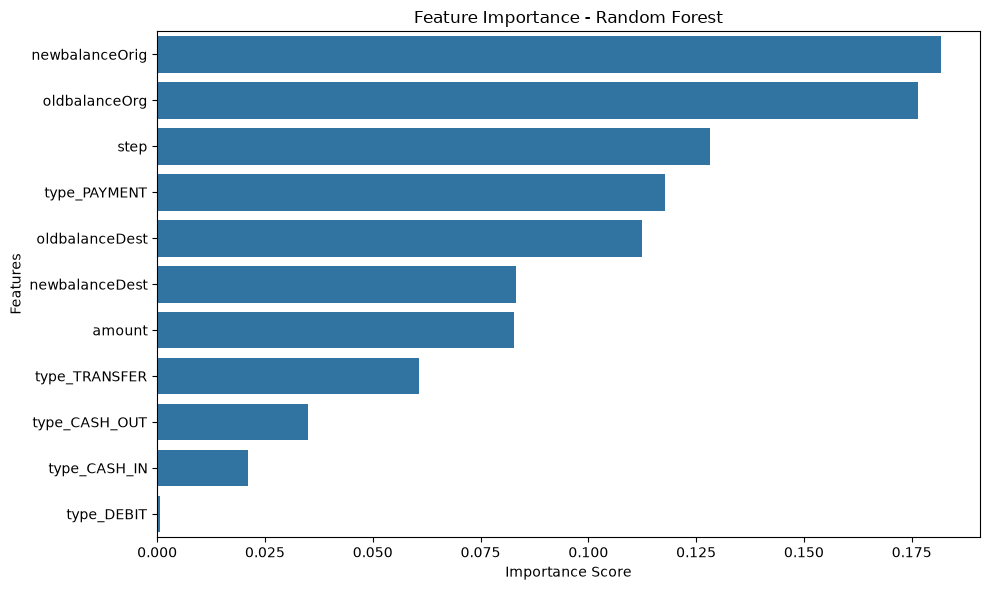

In [36]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [37]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [38]:
dt_pred = dt_model.predict(X_test)

print("First 20 Actual Values:")
print(y_test[:20].values)

print("\nFirst 20 Predicted Values:")
print(dt_pred[:20])

First 20 Actual Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 Predicted Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [39]:
from sklearn.metrics import classification_report, confusion_matrix

print("Decision Tree Classification Report:")
print(classification_report(y_test, dt_pred))

print("\nDecision Tree Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19977
           1       0.81      0.57      0.67        23

    accuracy                           1.00     20000
   macro avg       0.91      0.78      0.83     20000
weighted avg       1.00      1.00      1.00     20000


Decision Tree Confusion Matrix:
[[19974     3]
 [   10    13]]


In [40]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

ModuleNotFoundError: No module named 'tensorflow'

In [41]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:", X_train_scaled.shape)
print("Scaled Testing Data:", X_test_scaled.shape)

Scaled Training Data: (80000, 11)
Scaled Testing Data: (20000, 11)


In [43]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

ann_model = Sequential([
    Dense(16, activation='relu', input_shape=(11,)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

ann_model.summary()

c:\Users\meenutty\OneDrive\Desktop\Financial_Fraud_Detection\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


In [45]:
history = ann_model.fit(
    X_train_scaled,
    y_train,
    epochs=10,
    batch_size=256,
    validation_split=0.2,
    verbose=1
)

print("ANN training completed successfully!")

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9884 - loss: 0.1587 - val_accuracy: 0.9988 - val_loss: 0.0153
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9988 - loss: 0.0113 - val_accuracy: 0.9988 - val_loss: 0.0086
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9988 - loss: 0.0086 - val_accuracy: 0.9988 - val_loss: 0.0075
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9988 - loss: 0.0078 - val_accuracy: 0.9988 - val_loss: 0.0070
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9988 - loss: 0.0073 - val_accuracy: 0.9988 - val_loss: 0.0066
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9988 - loss: 0.0070 - val_accuracy: 0.9988 - val_loss: 0.0065
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9988 - loss: 0.0068 - val_accuracy: 0.9988 - val_loss: 0.0063
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9988 - loss: 0.0067 - val_accuracy: 0.

In [46]:
ann_test_proba = ann_model.predict(X_test_scaled).ravel()

ann_test_pred = (ann_test_proba >= 0.5).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print("ANN Classification Report:")
print(classification_report(y_test, ann_test_pred, zero_division=0))

print("\nANN Confusion Matrix:")
print(confusion_matrix(y_test, ann_test_pred))

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
ANN Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19977
           1       0.00      0.00      0.00        23

    accuracy                           1.00     20000
   macro avg       0.50      0.50      0.50     20000
weighted avg       1.00      1.00      1.00     20000


ANN Confusion Matrix:
[[19977     0]
 [   23     0]]


In [47]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.5005819264895441), np.int64(1): np.float64(430.10752688172045)}


In [48]:
history = ann_model.fit(
    X_train_scaled,
    y_train,
    epochs=10,
    batch_size=256,
    validation_split=0.2,
    class_weight=class_weights,
    verbose=1
)

print("ANN retraining completed successfully!")

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9755 - loss: 0.7077 - val_accuracy: 0.9190 - val_loss: 0.1857
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8925 - loss: 0.4311 - val_accuracy: 0.8606 - val_loss: 0.2582
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8542 - loss: 0.3279 - val_accuracy: 0.8589 - val_loss: 0.2832
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8675 - loss: 0.2930 - val_accuracy: 0.8644 - val_loss: 0.2745
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8710 - loss: 0.2801 - val_accuracy: 0.8682 - val_loss: 0.2677
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8653 - loss: 0.2681 - val_accuracy: 0.8887 - val_loss: 0.2429
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8883 - loss: 0.2673 - val_accuracy: 0.8744 - val_loss: 0.2665
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8842 - loss: 0.2620 - val_accuracy: 0.

In [49]:
ann_test_proba = ann_model.predict(X_test_scaled).ravel()

ann_test_pred = (ann_test_proba >= 0.5).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print("ANN Classification Report:")
print(classification_report(y_test, ann_test_pred, zero_division=0))

print("\nANN Confusion Matrix:")
print(confusion_matrix(y_test, ann_test_pred))

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
ANN Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94     19977
           1       0.01      0.87      0.02        23

    accuracy                           0.89     20000
   macro avg       0.50      0.88      0.48     20000
weighted avg       1.00      0.89      0.94     20000


ANN Confusion Matrix:
[[17848  2129]
 [    3    20]]


In [50]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

ann_scaler = StandardScaler()

X_subtrain_scaled = ann_scaler.fit_transform(X_subtrain)
X_val_scaled = ann_scaler.transform(X_val)

print("ANN training data:", X_subtrain_scaled.shape)
print("ANN validation data:", X_val_scaled.shape)

ANN training data: (64000, 11)
ANN validation data: (16000, 11)


In [51]:
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import numpy as np

classes = np.unique(y_subtrain)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_subtrain
)

ann_class_weights = dict(zip(classes, weights))

tuned_ann_model = Sequential([
    Dense(16, activation='relu', input_shape=(11,)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

tuned_ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = tuned_ann_model.fit(
    X_subtrain_scaled,
    y_subtrain,
    epochs=10,
    batch_size=256,
    class_weight=ann_class_weights,
    verbose=1
)

print("Tuned ANN training completed!")

c:\Users\meenutty\OneDrive\Desktop\Financial_Fraud_Detection\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9216 - loss: 0.8057
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9482 - loss: 0.5953
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9107 - loss: 0.5048
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8932 - loss: 0.4016
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7954 - loss: 0.3069
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8500 - loss: 0.2753
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8505 - loss: 0.2606
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8776 - loss: 0.2512
Epoch 9/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8500 - loss: 0.2460
Epoch 10/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8661 - loss: 0.2421
Tuned ANN training completed!


In [52]:
ann_val_proba = tuned_ann_model.predict(X_val_scaled).ravel()

print("First 10 validation fraud probabilities:")
print(ann_val_proba[:10])

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
First 10 validation fraud probabilities:
[1.7589323e-01 9.4816047e-01 4.3107548e-01 5.1198574e-04 3.1244033e-04
 1.0154523e-03 4.0651660e-02 2.4701306e-04 1.6913148e-09 4.2739586e-04]


In [53]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for threshold in thresholds:
    val_pred = (ann_val_proba >= threshold).astype(int)

    precision = precision_score(y_val, val_pred, zero_division=0)
    recall = recall_score(y_val, val_pred, zero_division=0)
    f1 = f1_score(y_val, val_pred, zero_division=0)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1-score: {f1:.3f}"
    )

Threshold: 0.1 | Precision: 0.003 | Recall: 0.947 | F1-score: 0.006
Threshold: 0.2 | Precision: 0.004 | Recall: 0.947 | F1-score: 0.008
Threshold: 0.3 | Precision: 0.006 | Recall: 0.947 | F1-score: 0.011
Threshold: 0.4 | Precision: 0.009 | Recall: 0.947 | F1-score: 0.017
Threshold: 0.5 | Precision: 0.011 | Recall: 0.947 | F1-score: 0.022
Threshold: 0.6 | Precision: 0.015 | Recall: 0.947 | F1-score: 0.030
Threshold: 0.7 | Precision: 0.025 | Recall: 0.842 | F1-score: 0.049
Threshold: 0.8 | Precision: 0.032 | Recall: 0.789 | F1-score: 0.062
Threshold: 0.9 | Precision: 0.056 | Recall: 0.684 | F1-score: 0.103


In [54]:
X_test_ann_scaled = ann_scaler.transform(X_test)

ann_final_proba = tuned_ann_model.predict(
    X_test_ann_scaled
).ravel()

ann_final_threshold = 0.9

ann_final_pred = (
    ann_final_proba >= ann_final_threshold
).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print("Final ANN Classification Report:")
print(classification_report(
    y_test,
    ann_final_pred,
    zero_division=0
))

print("\nFinal ANN Confusion Matrix:")
print(confusion_matrix(y_test, ann_final_pred))

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Final ANN Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     19977
           1       0.05      0.70      0.09        23

    accuracy                           0.98     20000
   macro avg       0.52      0.84      0.54     20000
weighted avg       1.00      0.98      0.99     20000


Final ANN Confusion Matrix:
[[19659   318]
 [    7    16]]


In [55]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'ANN'
    ],
    'Precision': [
        0.02, 0.81, 0.94, 0.05
    ],
    'Recall': [
        0.96, 0.57, 0.65, 0.70
    ],
    'F1 Score': [
        0.03, 0.67, 0.77, 0.09
    ]
})

print(model_comparison)

                 Model  Precision  Recall  F1 Score
0  Logistic Regression       0.02    0.96      0.03
1        Decision Tree       0.81    0.57      0.67
2        Random Forest       0.94    0.65      0.77
3                  ANN       0.05    0.70      0.09


In [56]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

rf_cv_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = ['precision', 'recall', 'f1']

cv_results = cross_validate(
    rf_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Average Cross-Validation Results:")
print("Precision:", cv_results['test_precision'].mean())
print("Recall:", cv_results['test_recall'].mean())
print("F1 Score:", cv_results['test_f1'].mean())

Average Cross-Validation Results:
Precision: 0.8042232277526395
Recall: 0.5450292397660819
F1 Score: 0.6357323232323232


In [57]:

from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully!")

GridSearchCV imported successfully!


In [58]:
param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

print("Parameter grid created successfully!")

Parameter grid created successfully!


In [59]:
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=1,
    verbose=1
)

print("GridSearchCV configured successfully!")

GridSearchCV configured successfully!


In [60]:
grid_search.fit(X_train, y_train)

print("GridSearchCV completed successfully!")

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
GridSearchCV completed successfully!

Best Parameters:
{'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}

Best Cross-Validation F1 Score:
0.6696586782861292


In [61]:
best_rf_model = grid_search.best_estimator_

print("Tuned Random Forest model created!")


Tuned Random Forest model created!


In [62]:
from sklearn.metrics import classification_report, confusion_matrix

tuned_rf_pred = best_rf_model.predict(X_test)

print("Tuned Random Forest Classification Report:")
print(classification_report(
    y_test,
    tuned_rf_pred,
    zero_division=0
))

print("\nTuned Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, tuned_rf_pred))

Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19977
           1       0.91      0.43      0.59        23

    accuracy                           1.00     20000
   macro avg       0.95      0.72      0.79     20000
weighted avg       1.00      1.00      1.00     20000


Tuned Random Forest Confusion Matrix:
[[19976     1]
 [   13    10]]


In [63]:
import joblib

joblib.dump(final_rf_model, 'fraud_detection_model.pkl')

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [64]:
joblib.dump(
    {
        'threshold': 0.4,
        'features': X_train.columns.tolist()
    },
    'model_config.pkl'
)

print("Model configuration saved successfully!")

Model configuration saved successfully!
